# Can a Lame Duck Still Walk?

Faults on the left knee servo of the MicroDuck, set through parameters of the Modelica plant
`fmu/DuckPlant.fmu`, with the trained policy `velstand.onnx` running here in Python at 50 Hz. Three single
faults, then a sweep of the knee's supply voltage down to the point where the robot falls.

This notebook produces every number, figure and the animation of the post into `images/`.
[Setup and files](README.md).

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd()))
from common import *  # noqa: F403  FMU walk, plot style

%matplotlib inline
IMAGES = Path("images")
IMAGES.mkdir(exist_ok=True)
FALLEN_HEIGHT = 0.09  # trunk height below which the robot has fallen [m]


def fall_time(df):
    fallen = df["time"][df["trunkHeight"] < FALLEN_HEIGHT]
    return fallen.iloc[0] if len(fallen) else np.nan


def knee_error(df):
    """RMS tracking error of the left knee over the last 4 s [deg]."""
    late = df["time"] >= 2
    return np.sqrt((np.degrees(df["qRef[4]"] - df["q[4]"])[late] ** 2).mean())


def summary(df):
    walking = np.isnan(fall_time(df))
    return {"speed, last 4 s [m/s]": speed(df) if walking else np.nan,
            "distance, 6 s [m]": df["distance"].iloc[-1] if walking else np.nan,
            "knee error RMS [deg]": knee_error(df) if walking else np.nan,
            "lowest trunk [mm]": 1e3 * df["trunkHeight"].min() if walking else np.nan,
            "falls at [s]": fall_time(df)}

## Three faults on one knee

Worn gear (6° of play instead of 2°), weak motor (3.7 V instead of 7.4 V) and an unpowered motor (drive
fraction zero), each present from the start of a 6 s walk at a 0.3 m/s command.

In [2]:
CASES = {
    "Healthy": {},
    "Left knee, 6° play": {"kneeBacklash": np.radians(6)},
    "Left knee at 3.7 V": {"kneeSupply": 3.7},
    "Left knee unpowered": {"kneeGain": 0},
}
runs = {name: walk_fmu(**parameters) for name, parameters in CASES.items()}
pd.DataFrame({name: summary(df) for name, df in runs.items()}).T.round(3)

,"speed, last 4 s [m/s]","distance, 6 s [m]",knee error RMS [deg],lowest trunk [mm],falls at [s]
Healthy,0.137,0.798,23.756,111.266,NaN
"Left knee, 6° play",0.136,0.801,25.195,111.277,NaN
Left knee at 3.7 V,0.114,0.697,31.030,109.876,NaN
Left knee unpowered,NaN,NaN,NaN,NaN,0.84


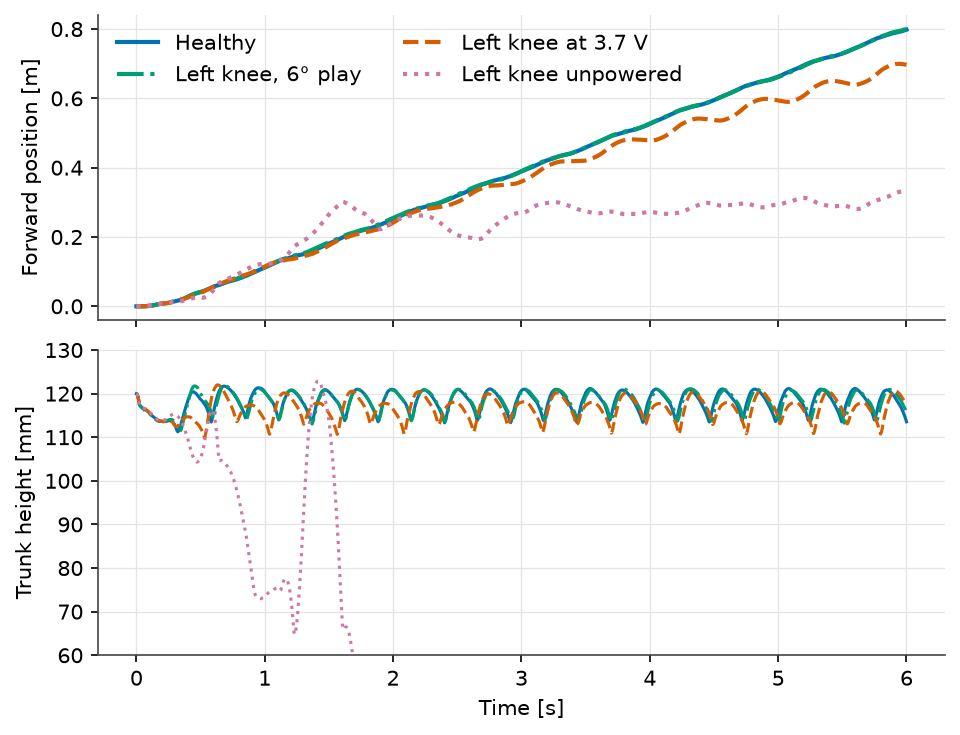

In [3]:
fig, (a1, a2) = plt.subplots(2, 1, figsize=(6.5, 5.0), sharex=True)
for (name, df), c, ls in zip(runs.items(), [BLUE, GREEN, ORANGE, PINK], ["-", "-.", "--", ":"]):
    a1.plot(df["time"], df["distance"], color=c, ls=ls, label=name)
    a2.plot(df["time"], 1e3 * df["trunkHeight"], color=c, ls=ls, lw=1.5)
a1.set_ylabel("Forward position [m]")
a1.legend(loc="upper left", ncol=2)
a2.set_ylabel("Trunk height [mm]")
a2.set_ylim(60, 130)
a2.set_xlabel("Time [s]")
fig.tight_layout()
fig.savefig(IMAGES / "faults.png")
plt.show()

## How lame is too lame?

Lower the left knee's supply from 7.4 V towards zero, everything else healthy. 7.4 V and 3.7 V are the runs
above, and 0 V is the unpowered knee: with no supply the drive is zero either way.

In [4]:
sweep = {7.4: runs["Healthy"], 3.7: runs["Left knee at 3.7 V"], 0.0: runs["Left knee unpowered"]}
for v in [6.0, 5.0, 4.5, 3.0, 2.5, 2.0, 1.5, 1.0, 0.5]:
    sweep[v] = walk_fmu(kneeSupply=v)
sweep = dict(sorted(sweep.items(), reverse=True))
pd.DataFrame({f"{v:.1f} V": summary(df) for v, df in sweep.items()}).T.round(3)

,"speed, last 4 s [m/s]","distance, 6 s [m]",knee error RMS [deg],lowest trunk [mm],falls at [s]
7.4 V,0.137,0.798,23.756,111.266,NaN
6.0 V,0.136,0.791,25.526,111.863,NaN
5.0 V,0.135,0.781,27.767,111.641,NaN
4.5 V,0.129,0.755,28.985,111.150,NaN
3.7 V,0.114,0.697,31.030,109.876,NaN
3.0 V,0.110,0.680,35.177,108.358,NaN
2.5 V,0.108,0.648,38.130,107.098,NaN
2.0 V,0.021,0.279,44.205,105.684,NaN
1.5 V,-0.020,0.113,55.698,101.476,NaN
1.0 V,NaN,NaN,NaN,NaN,2.065


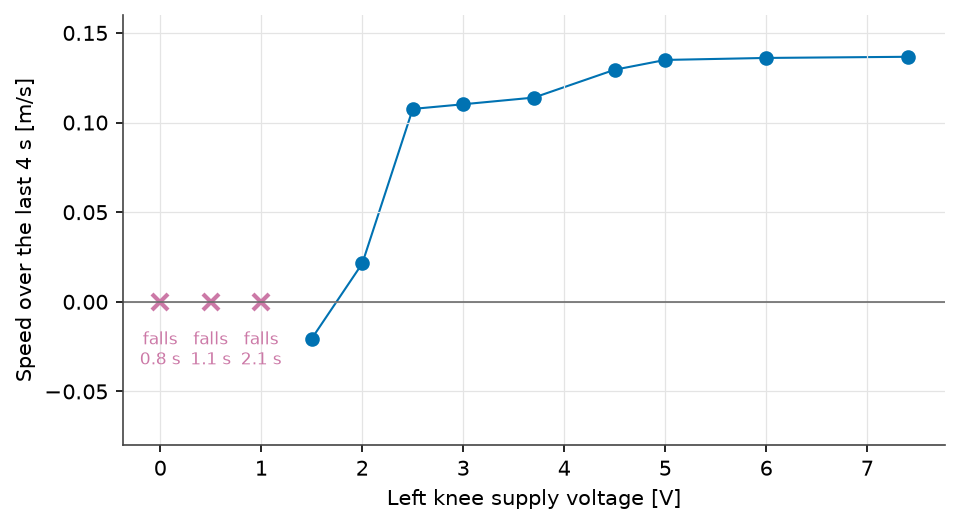

left knee stiffness at 2.5 V: 0.20 N·m/rad


In [5]:
fig, ax = plt.subplots(figsize=(6.5, 3.6))
walking = [v for v, df in sweep.items() if np.isnan(fall_time(df))]
ax.plot(walking, [speed(sweep[v]) for v in walking], color=BLUE, lw=1, zorder=0)
ax.plot(walking, [speed(sweep[v]) for v in walking], "o", color=BLUE, ms=6)
for v, df in sweep.items():
    if not np.isnan(fall_time(df)):
        ax.plot(v, 0, "x", color=PINK, ms=8, mew=2)
        ax.annotate("falls" + chr(10) + f"{fall_time(df):.1f} s", (v, 0), xytext=(0, -30),
                    textcoords="offset points", ha="center", fontsize=8, color=PINK)
ax.axhline(0, color=GREY, lw=0.8)
ax.set_xlabel("Left knee supply voltage [V]")
ax.set_ylabel("Speed over the last 4 s [m/s]")
ax.set_ylim(-0.08, 0.16)
fig.tight_layout()
fig.savefig(IMAGES / "knee_sweep.png")
plt.show()
K_HEALTHY = 0.589  # servo stiffness at 7.4 V and gain 200 [N·m/rad], Part 1; proportional to the supply
print(f"left knee stiffness at 2.5 V: {K_HEALTHY * 2.5 / 7.4:.2f} N·m/rad")

## Animation

Six of the walks side by side at half speed, drawn with the robot meshes of the MuJoCo training model from
the plant's trunk position, trunk angles and joint angles. The left shank, driven by the faulty knee, is
tinted pink. A robot that falls is held where its trunk drops below 90 mm: only the soles collide, so the
trunk would pass through the floor afterwards.

In [6]:
import mujoco
from PIL import Image, ImageDraw, ImageFont

SHOWN = [("Healthy", runs["Healthy"]), ("Left knee, 6° play", runs["Left knee, 6° play"]),
         ("Left knee at 3.7 V", sweep[3.7]), ("Left knee at 2.5 V", sweep[2.5]),
         ("Left knee at 2.0 V", sweep[2.0]), ("Left knee unpowered", sweep[0.0])]
PANEL_W, VIEW_H, BAR_H, HEADER_H, COLUMNS = 300, 240, 40, 30, 3
SAMPLE = 0.04  # 40 ms of walking per GIF frame
FRAME_MS = 80  # so the GIF plays at half speed
TRACK = 0.85  # length of the progress bar [m]
SHELL, FAULT = np.array([0.80, 0.81, 0.83]), np.array([0xCC, 0x79, 0xA7]) / 255
BACKGROUND, INK, MUTED = (246, 247, 249), (34, 34, 34), (110, 110, 110)
LEFT_KNEE = 3


def planar_rotation(axis, angle):
    e = np.eye(3)[axis]
    skew = np.array([[0, -e[2], e[1]], [e[2], 0, -e[0]], [-e[1], e[0], 0]])
    return np.outer(e, e) + (np.eye(3) - np.outer(e, e)) * np.cos(angle) - skew * np.sin(angle)


def trunk_to_world(phi):
    """Rotation matrix of the trunk frame in the world frame from the plant's Cardan angles (sequence 1, 2, 3)."""
    world_to_trunk = planar_rotation(2, phi[2]) @ planar_rotation(1, phi[1]) @ planar_rotation(0, phi[0])
    return world_to_trunk.T


spec = mujoco.MjSpec.from_file(str(MUJOCO_SCENE))
for texture in spec.textures:
    if texture.name == "groundplane":  # plain floor: the bars show progress, and the GIF stays small
        texture.rgb1 = texture.rgb2 = texture.markrgb = [0.91, 0.92, 0.94]
    else:
        texture.rgb1 = texture.rgb2 = [0.965, 0.97, 0.98]
for material in spec.materials:
    if material.name == "groundplane":
        material.reflectance, material.specular = 0.0, 0.0
model = spec.compile()
model.light_diffuse[:], model.light_specular[:], model.light_ambient[:] = 0.3, 0.0, 0.0
model.vis.headlight.diffuse[:], model.vis.headlight.ambient[:] = 0.3, 0.5
model.vis.rgba.haze[:] = [0.965, 0.97, 0.98, 1.0]
model.vis.global_.offwidth, model.vis.global_.offheight = PANEL_W, VIEW_H
data = mujoco.MjData(model)
qadr = [model.jnt_qposadr[model.joint(j).id] for j in MUJOCO_JOINTS]
link_geoms = []
for j in MUJOCO_JOINTS:
    body = model.jnt_bodyid[model.joint(j).id]
    geoms = [g for g in range(model.ngeom) if model.geom_bodyid[g] == body and model.geom_group[g] == 2]
    model.geom_matid[geoms] = -1
    link_geoms.append(geoms)

times = np.arange(0, 6 + 1e-9, SAMPLE)
panels = []
for label, df in SHOWN:
    t_fall = fall_time(df)
    shown = np.minimum(times, t_fall) if not np.isnan(t_fall) else times  # hold a fallen robot

    def at(column):
        return np.interp(shown, df["time"], df[column])

    panels.append({"label": label, "fall": t_fall, "held": times >= t_fall,
                   "position": np.stack([at(f"trunkJoint.r_rel_a[{i}]") for i in (1, 2, 3)], axis=1),
                   "phi": np.stack([at(f"trunkJoint.phi[{i}]") for i in (1, 2, 3)], axis=1),
                   "q": np.stack([at(f"q[{i}]") for i in range(1, 15)], axis=1)})

renderer = mujoco.Renderer(model, VIEW_H, PANEL_W)
camera = mujoco.MjvCamera()
camera.azimuth, camera.elevation, camera.distance = 105.0, -10.0, 0.62
font, small = ImageFont.load_default(size=15), ImageFont.load_default(size=12)
rows = -(-len(SHOWN) // COLUMNS)
frames = []
for k, t in enumerate(times):
    frame = Image.new("RGB", (COLUMNS * PANEL_W, HEADER_H + rows * (VIEW_H + BAR_H)), BACKGROUND)
    draw = ImageDraw.Draw(frame)
    draw.text((12, 8), "Modelica, MicroDuck library", fill=INK, font=font)
    draw.text((frame.width - 12, 10), f"t = {t:.1f} s, half speed", fill=INK, font=small, anchor="ra")
    for i, p in enumerate(panels):
        data.qpos[:3] = p["position"][k]
        mujoco.mju_mat2Quat(data.qpos[3:7], trunk_to_world(p["phi"][k]).flatten())
        data.qpos[qadr] = p["q"][k]
        for g, geoms in enumerate(link_geoms):
            model.geom_rgba[geoms, :3] = FAULT if (g == LEFT_KNEE and i > 0) else SHELL
        mujoco.mj_forward(model, data)
        camera.lookat[:] = [p["position"][k][0], p["position"][k][1], 0.13]
        renderer.update_scene(data, camera)
        x0, y0 = (i % COLUMNS) * PANEL_W, HEADER_H + (i // COLUMNS) * (VIEW_H + BAR_H)
        frame.paste(Image.fromarray(renderer.render()), (x0, y0))
        draw.text((x0 + 12, y0 + 10), p["label"], fill=INK, font=font)
        if p["held"][k]:
            draw.text((x0 + 12, y0 + 30), f"falls at {p['fall']:.2f} s", fill=tuple(int(255 * c) for c in FAULT),
                      font=small)
        x = p["position"][k][0]
        bx, by, bw = x0 + 12, y0 + VIEW_H + 14, PANEL_W - 24
        dot = bx + bw * np.clip(x / TRACK, 0, 1)
        draw.line([(bx, by), (bx + bw, by)], fill=(200, 202, 206), width=4)
        draw.ellipse([dot - 5, by - 5, dot + 5, by + 5], fill=(0, 114, 178))
        draw.text((bx, by + 10), f"x = {x:.2f} m", fill=MUTED, font=small)
    frames.append(frame.quantize(colors=128, method=Image.Quantize.MEDIANCUT, dither=Image.Dither.NONE))
renderer.close()
frames += [frames[-1]] * 20  # hold the final state for 1.6 s
frames[0].save(IMAGES / "lame_walk.gif", save_all=True, append_images=frames[1:], duration=FRAME_MS, loop=0,
               optimize=True, disposal=1)
print(f"{len(frames)} frames, {(IMAGES / 'lame_walk.gif').stat().st_size / 1e6:.1f} MB")

171 frames, 4.0 MB


![Six MicroDucks walking side by side, from a healthy left knee to an unpowered one](images/lame_walk.gif)

Equivalent runs differ by about ±5% in the speed over the last 4 s: delaying each command by 23 ms
instead of 22.5 ms is enough. A few percent between the cases above is noise, not a finding.

## Hero image

Three of the walks over the first 3 s at real speed, on the light grid floor of the NousLogo example: healthy, the
left knee at 2.5 V, and the unpowered knee, held where it falls. The robots are yellow with their dark servos kept,
and the faulty left shank is blue.

In [7]:
HERO_W, HERO_H, HERO_BAND, HERO_COLORS, HERO_END = 360, 400, 36, 128, 3.0
HERO = [("Healthy", sweep[7.4]), ("Left knee at 2.5 V", sweep[2.5]), ("Left knee unpowered", sweep[0.0])]
hero_spec = mujoco.MjSpec.from_file(str(MUJOCO_SCENE))
for texture in hero_spec.textures:  # the light grid floor of the NousLogo example
    if texture.name == "groundplane":
        texture.rgb1 = texture.rgb2 = [0.91, 0.92, 0.94]
        texture.markrgb = [0.55, 0.58, 0.63]
    else:
        texture.rgb1 = texture.rgb2 = [0.965, 0.97, 0.98]
for material in hero_spec.materials:
    if material.name == "groundplane":
        material.reflectance, material.specular, material.texrepeat = 0.0, 0.0, [10, 10]
fault_material = hero_spec.add_material(name="fault")
fault_material.rgba = [0.0, 0.27, 0.80, 1.0]
body_material = hero_spec.add_material(name="body")
body_material.rgba = [0.98, 0.78, 0.10, 1.0]
fault_material.emission = 0.3  # so the dim scene light does not darken the shank into the servos
hero_model = hero_spec.compile()
hero_model.light_diffuse[:], hero_model.light_specular[:], hero_model.light_ambient[:] = 0.3, 0.0, 0.0
hero_model.vis.headlight.diffuse[:], hero_model.vis.headlight.ambient[:] = 0.3, 0.5
hero_model.vis.rgba.haze[:] = [0.965, 0.97, 0.98, 1.0]
hero_model.vis.global_.offwidth, hero_model.vis.global_.offheight = HERO_W, HERO_H
hero_data = mujoco.MjData(hero_model)
for g in range(hero_model.ngeom):
    if hero_model.geom_bodyid[g] > 0 and hero_model.geom_group[g] == 2:
        matid = hero_model.geom_matid[g]
        rgb = hero_model.mat_rgba[matid, :3] if matid >= 0 else hero_model.geom_rgba[g, :3]
        if rgb @ [0.299, 0.587, 0.114] > 0.4:  # recolour shells and brackets, keep the dark servos for the joints
            hero_model.geom_matid[g] = hero_model.material("body").id
            hero_model.geom_rgba[g] = body_material.rgba
knee_body = hero_model.jnt_bodyid[hero_model.joint(MUJOCO_JOINTS[LEFT_KNEE]).id]
knee_geoms = [g for g in range(hero_model.ngeom)
              if hero_model.geom_bodyid[g] == knee_body and hero_model.geom_group[g] == 2]
knee_material, knee_rgba = hero_model.geom_matid[knee_geoms].copy(), hero_model.geom_rgba[knee_geoms].copy()
renderer = mujoco.Renderer(hero_model, HERO_H, HERO_W)
camera = mujoco.MjvCamera()
camera.azimuth, camera.elevation, camera.distance = 140.0, -15.0, 0.60  # as Part 1
label_font = ImageFont.load_default(size=18)
hero_frames = []
for t_frame in np.arange(0, HERO_END + 1e-9, SAMPLE):
    hero = Image.new("RGB", (len(HERO) * HERO_W, HERO_H + HERO_BAND), (234, 236, 240))
    draw = ImageDraw.Draw(hero)
    for i, (label, df) in enumerate(HERO):
        t_fall = fall_time(df)
        t = np.nanmin([t_frame, t_fall])

        def at(column):
            return np.interp(t, df["time"], df[column])

        position = [at(f"trunkJoint.r_rel_a[{k}]") for k in (1, 2, 3)]
        hero_data.qpos[:3] = position
        mujoco.mju_mat2Quat(hero_data.qpos[3:7],
                            trunk_to_world([at(f"trunkJoint.phi[{k}]") for k in (1, 2, 3)]).flatten())
        hero_data.qpos[qadr] = [at(f"q[{k}]") for k in range(1, 15)]
        if i > 0:
            # a geom rgba other than the default overrides its material's colour, so set both
            hero_model.geom_matid[knee_geoms] = hero_model.material("fault").id
            hero_model.geom_rgba[knee_geoms] = fault_material.rgba
        else:
            hero_model.geom_matid[knee_geoms], hero_model.geom_rgba[knee_geoms] = knee_material, knee_rgba
        mujoco.mj_forward(hero_model, hero_data)
        camera.lookat[:] = [position[0], position[1], 0.12]
        renderer.update_scene(hero_data, camera)
        hero.paste(Image.fromarray(renderer.render()), (i * HERO_W, 0))
        draw.text((i * HERO_W + HERO_W // 2, HERO_H + 25), label, fill=INK, font=label_font, anchor="ms")
    hero_frames.append(hero)
renderer.close()
# One palette from frames across the loop keeps the magenta shank and stops colours flickering between frames
sheet = Image.new("RGB", (hero_frames[0].width, 4 * hero_frames[0].height))
for j, frame in enumerate(hero_frames[::len(hero_frames) // 4][:4]):
    sheet.paste(frame, (0, j * frame.height))
palette = sheet.quantize(colors=HERO_COLORS, method=Image.Quantize.MEDIANCUT)
hero_frames = [frame.quantize(palette=palette, dither=Image.Dither.NONE) for frame in hero_frames]
hero_frames += [hero_frames[-1]] * 12  # hold the final state for about 0.5 s
hero_frames[0].save(IMAGES / "hero.gif", save_all=True, append_images=hero_frames[1:],
                    duration=int(1000 * SAMPLE), loop=0, optimize=True, disposal=1)
print(f"{len(hero_frames)} frames, {(IMAGES / 'hero.gif').stat().st_size / 1e6:.1f} MB")

88 frames, 2.6 MB
